# Trabalho Prático 2: Reconhecimento de Objetos e Recuperação de Imagens
## Parte 4 — Representações Visuais Pré-treinadas: CNN, DINOv2 e CLIP

Este notebook implementa e responde a todas as etapas e questões do enunciado da **Parte 4**:
- **Stage A:** Características convolucionais congeladas (ResNet-18) com GAP nas últimas camadas (`layer2.1`, `layer3.1`, `layer4.1`) e combinação (`layers2-4`).
- **Stage B:** DINOv2 (`dinov2_vits14`) — extração do token global `[CLS]` e comparação com patch tokens.
- **Stage C:** Few-shot learning (1, 5, 10, 20 exemplos positivos) e impacto de data augmentation (horizontal flip).
- **Stage D:** Seleção de hiperparâmetros (C no SVM linear) utilizando exclusivamente a validação interna.
- **Stage E:** CLIP zero-shot classification (`clip_vit_b_32`), matriz de confusão e engenharia de prompts.
- **Stage F:** Análise visual, mapas de ativação/saliência (CAM na ResNet-18) e diagnóstico de falhas / viés de contexto.

In [1]:
import os
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import clip

from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    ConfusionMatrixDisplay
)

# Importação dos utilitários do projeto
from src.deep_models import getModel, IntermediateFeatureExtractor

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo configurado: {DEVICE}")

Dispositivo configurado: cuda


## 1. Configuração de Dados e Dicionário de Representações (`REPS`)
Para ser 100% compatível com as features já guardadas em `data/features/*.npz`, definimos o mapeamento de representações exatamente como no repositório:
- As chaves dos ficheiros `.npz` da ResNet-18 são `layer1.1`, `layer2.1`, `layer3.1`, `layer4.1`.
- A representação `layers2-4` é obtida concatenando horizontalmente `layer2.1`, `layer3.1` e `layer4.1` dinamicamente.

In [3]:
DATA_DIR = "data"
IMAGES_DIR = os.path.join(DATA_DIR, "images")
FEAT_CACHE_DIR = os.path.join(DATA_DIR, "features")
BASE_ENC = "bovw_K512_C0"
CATEGORIES = ["motorbike", "aeroplane", "person"]
CLASSES_MC = CATEGORIES + ["background"]
DEV_SEED = 42
SEEDS = (0, 1, 2)

# Mapeamento exato de representações e das respetivas chaves no ficheiro .npz
RESNET_LAYERS = ["layer1.1", "layer2.1", "layer3.1", "layer4.1"]

REPS = {
    "ResNet18 layer2.1":      ("resnet18", ("layer2.1",)),
    "ResNet18 layer3.1":      ("resnet18", ("layer3.1",)),
    "ResNet18 layer4.1":      ("resnet18", ("layer4.1",)),
    "ResNet18 layers2-4":     ("resnet18", ("layer2.1", "layer3.1", "layer4.1")),
    "ViT-B/32 (torchvision)": ("vit_b32",  ("cls",)),
    "DINOv2 ViT-S/14 CLS":    ("dinov2",   ("cls",)),
    "DINOv2 CLS+patch-mean":  ("dinov2",   ("cls", "patch_mean")),
    "CLIP ViT-B/32 image":    ("clip",     ("img",)),
}

def load_names(category, subset="train"):
    """Carrega ficheiros positivos da categoria (+1) e negativos do background (-1)."""
    base_path = os.path.join(DATA_DIR, "encodings", BASE_ENC)
    p = np.load(os.path.join(base_path, f"{category}_{subset}.npz"))["file_names"]
    n = np.load(os.path.join(base_path, f"background_{subset}.npz"))["file_names"]
    names = np.concatenate([p, n])
    y = np.concatenate([np.ones(len(p), dtype=int), -np.ones(len(n), dtype=int)])
    return names, y

def dev_split_names(category, seed=DEV_SEED, val_size=0.2):
    """Divisão estratificada inner-train / inner-val (80/20) sem tocar no teste final."""
    names, y = load_names(category, "train")
    sss = StratifiedShuffleSplit(n_splits=1, test_size=val_size, random_state=seed)
    idx_tr, idx_va = next(sss.split(names, y))
    return names[idx_tr], y[idx_tr], names[idx_va], y[idx_va]

# Armazenamento em memória dos arquivos .npz para acesso rápido
_FSTORE = {}

def get_cached_features(model_key, flip=False):
    tag = model_key + ("_flip" if flip else "")
    path = os.path.join(FEAT_CACHE_DIR, f"{tag}.npz")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Ficheiro de features não encontrado: {path}. Verifique a extração prévia.")
    if (model_key, flip) not in _FSTORE:
        z = np.load(path)
        idx = {str(n): i for i, n in enumerate(z["file_names"].tolist())}
        _FSTORE[(model_key, flip)] = (idx, z)
    return _FSTORE[(model_key, flip)]

def rep_matrix(rep, names, flip=False):
    """Monta a matriz X concatenando as chaves especificadas em REPS."""
    model_key, keys = REPS[rep]
    idx, z = get_cached_features(model_key, flip)
    rows = [idx[str(n)] for n in names]
    # Concatena horizontalmente se houver múltiplas chaves (ex.: layer2.1 + layer3.1 + layer4.1)
    return np.hstack([z[k][rows] for k in keys]).astype(np.float32)

def l2_norm(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-10)

def fit_norm(Xtr, norm_type):
    if norm_type == "l2":
        return l2_norm
    scaler = StandardScaler().fit(Xtr)
    return lambda X: l2_norm(scaler.transform(X))

for r in REPS:
    sample_names, _ = load_names(CATEGORIES[0], "train")
    print(f"{r:25s} -> dimensão = {rep_matrix(r, sample_names[:2]).shape[1]}")

ResNet18 layer2.1         -> dimensão = 128
ResNet18 layer3.1         -> dimensão = 256
ResNet18 layer4.1         -> dimensão = 512
ResNet18 layers2-4        -> dimensão = 896
ViT-B/32 (torchvision)    -> dimensão = 768
DINOv2 ViT-S/14 CLS       -> dimensão = 384
DINOv2 CLS+patch-mean     -> dimensão = 768
CLIP ViT-B/32 image       -> dimensão = 512


## 4. Stage A — Frozen CNN Features (ResNet-18)


In [16]:
def eval_dev_ap(rep, category, norm_type, seed=DEV_SEED, C=1.0):
    ntr, ytr, nva, yva = dev_split_names(category, seed=seed)
    Xtr = rep_matrix(rep, ntr)
    Xva = rep_matrix(rep, nva)
    
    fn = fit_norm(Xtr, norm_type)
    Xtr_n = fn(Xtr)
    Xva_n = fn(Xva)
    
    t0 = time.perf_counter()
    clf = LinearSVC(C=C, max_iter=5000, random_state=42)
    clf.fit(Xtr_n, ytr)
    t_train = time.perf_counter() - t0
    
    scores = clf.decision_function(Xva_n)
    ap = average_precision_score(np.asarray(yva) > 0, scores)
    return {"ap": ap, "t_train": t_train, "dim": Xtr.shape[1]}

# Avaliação com a seed fixa 42
resnet_candidates = ["ResNet18 layer2.1", "ResNet18 layer3.1", "ResNet18 layer4.1", "ResNet18 layers2-4"]
rows_stageA_dev = []

for rep in resnet_candidates:
    for norm in ["l2", "std"]:
        cat_aps = {c: eval_dev_ap(rep, c, norm, seed=DEV_SEED, C=1.0)["ap"] for c in CATEGORIES}
        m_ap = np.mean(list(cat_aps.values()))
        t_mean = np.mean([eval_dev_ap(rep, c, norm, seed=DEV_SEED, C=1.0)["t_train"] for c in CATEGORIES])
        dim = eval_dev_ap(rep, CATEGORIES[0], norm, seed=DEV_SEED, C=1.0)["dim"]
        
        rows_stageA_dev.append({
            "Representação": rep,
            "Normalização": norm,
            "Dimensão": dim,
            "mAP (seed 42)": m_ap,
            "Tempo Treino (s)": t_mean,
            **cat_aps
        })

df_stageA_dev = pd.DataFrame(rows_stageA_dev)
display(df_stageA_dev.round(4))

,Representação,Normalização,Dimensão,mAP (seed 42),Tempo Treino (s),motorbike,aeroplane,person
0,ResNet18 layer2.1,l2,128,0.8271,0.0158,0.7967,0.7913,0.8933
1,ResNet18 layer2.1,std,128,0.8352,0.0156,0.8344,0.7677,0.9034
2,ResNet18 layer3.1,l2,256,0.9248,0.0339,0.9149,0.8756,0.9839
3,ResNet18 layer3.1,std,256,0.9278,0.0332,0.9031,0.9002,0.9800
4,ResNet18 layer4.1,l2,512,0.9803,0.0404,0.9673,0.9909,0.9825
5,ResNet18 layer4.1,std,512,0.9794,0.0366,0.9661,0.9923,0.9799
6,ResNet18 layers2-4,l2,896,0.9803,0.0638,0.9673,0.9909,0.9828
7,ResNet18 layers2-4,std,896,0.9803,0.0992,0.9694,0.9865,0.9849


In [24]:
import os
import json

def get_extraction_time_per_img(tag="resnet18"):
    timings_path = os.path.join(FEAT_CACHE_DIR, "timings.json")
    if os.path.exists(timings_path):
        with open(timings_path, "r") as f:
            t_data = json.load(f)
            if tag in t_data and "ms_per_img_forward" in t_data[tag]:
                return t_data[tag]["ms_per_img_forward"]
    return None

# Recuperar o tempo da ResNet-18
t_ext_ms_resnet = get_extraction_time_per_img("resnet18")
print(f"Tempo de extração ResNet-18: {t_ext_ms_resnet:.4f} ms/img" if t_ext_ms_resnet else "Tempo não encontrado.")

Tempo de extração ResNet-18: 0.6381 ms/img


In [3]:
def dev_ap(rep, category, norm_type, seed, C=1.0):
    ntr, ytr, nva, yva = dev_split_names(category, seed=seed)
    Xtr = rep_matrix(rep, ntr)
    Xva = rep_matrix(rep, nva)
    
    fn = fit_norm(Xtr, norm_type)
    Xtr_n = fn(Xtr)
    Xva_n = fn(Xva)
    
    t0 = time.perf_counter()
    clf = LinearSVC(C=C, max_iter=5000, random_state=42)
    clf.fit(Xtr_n, ytr)
    t_train = time.perf_counter() - t0
    
    scores = clf.decision_function(Xva_n)
    ap = average_precision_score(np.asarray(yva) > 0, scores)
    return {"ap": ap, "t_train": t_train, "dim": Xtr.shape[1]}

def dev_map(rep, norm_type, C=1.0):
    per_seed = [np.mean([dev_ap(rep, c, norm_type, s, C)["ap"] for c in CATEGORIES]) for s in SEEDS]
    return float(np.mean(per_seed)), float(np.std(per_seed))

resnet_candidates = ["ResNet18 layer2.1", "ResNet18 layer3.1", "ResNet18 layer4.1", "ResNet18 layers2-4"]
rows_stageA = []

for rep in resnet_candidates:
    for norm in ["l2", "std"]:
        m, sd = dev_map(rep, norm, C=1.0)
        per_cat = {c: np.mean([dev_ap(rep, c, norm, s, C=1.0)["ap"] for s in SEEDS]) for c in CATEGORIES}
        t_mean = np.mean([dev_ap(rep, c, norm, SEEDS[0], C=1.0)["t_train"] for c in CATEGORIES])
        dim = dev_ap(rep, CATEGORIES[0], norm, SEEDS[0], C=1.0)["dim"]
        
        rows_stageA.append({
            "Representação": rep,
            "Normalização": norm,
            "Dimensão": dim,
            "mAP": m,
            "mAP_std": sd,
            "Tempo Treino (s)": t_mean,
            **per_cat
        })

df_stageA = pd.DataFrame(rows_stageA)
display(df_stageA.round(4))

best_resnet = df_stageA.sort_values("mAP", ascending=False).iloc[0]["Representação"]
print("Melhor representação ResNet-18 (inner-val):", best_resnet)

,Representação,Normalização,Dimensão,mAP,mAP_std,Tempo Treino (s),motorbike,aeroplane,person
0,ResNet18 layer2.1,l2,128,0.7774,0.0185,0.0085,0.6965,0.7602,0.8755
1,ResNet18 layer2.1,std,128,0.8174,0.0264,0.0108,0.7520,0.8116,0.8886
2,ResNet18 layer3.1,l2,256,0.9153,0.0121,0.0146,0.8881,0.8901,0.9678
3,ResNet18 layer3.1,std,256,0.9300,0.0131,0.0158,0.9056,0.9232,0.9612
4,ResNet18 layer4.1,l2,512,0.9755,0.0002,0.0257,0.9632,0.9889,0.9744
5,ResNet18 layer4.1,std,512,0.9738,0.0014,0.0260,0.9640,0.9866,0.9709
6,ResNet18 layers2-4,l2,896,0.9756,0.0003,0.0503,0.9633,0.9889,0.9745
7,ResNet18 layers2-4,std,896,0.9745,0.0041,0.0532,0.9676,0.9837,0.9723


Melhor representação ResNet-18 (inner-val): ResNet18 layers2-4


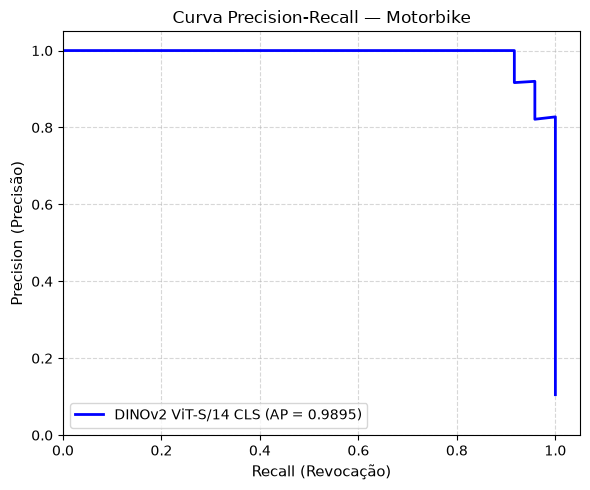

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, PrecisionRecallDisplay

# 1. Obter dados e representações
cat = "motorbike"
seed = 0
rep = "DINOv2 ViT-S/14 CLS"
norm = "l2"

ntr, ytr, nva, yva = dev_split_names(cat, seed=seed)
Xtr = l2_norm(rep_matrix(rep, ntr))
Xva = l2_norm(rep_matrix(rep, nva))

# 2. Treinar o classificador Linear SVM
clf = LinearSVC(C=1.0, max_iter=5000, random_state=seed)
clf.fit(Xtr, ytr)

# 3. Obter os scores de decisão contínuos (não as previsões binárias 0/1)
scores = clf.decision_function(Xva)
y_true_binary = (np.asarray(yva) > 0).astype(int)

# 4. Calcular Precisão, Revocação e AP
precision, recall, thresholds = precision_recall_curve(y_true_binary, scores)
ap = average_precision_score(y_true_binary, scores)

# 5. Visualizar a curva
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall, precision, color="b", lw=2, label=f"{rep} (AP = {ap:.4f})")
ax.set_xlabel("Recall (Revocação)", fontsize=11)
ax.set_ylabel("Precision (Precisão)", fontsize=11)
ax.set_title(f"Curva Precision-Recall — {cat.capitalize()}", fontsize=12)
ax.set_xlim([0.0, 1.05])
ax.set_ylim([0.0, 1.05])
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower left", fontsize=10)

plt.tight_layout()
plt.show()

## 4. Stage B — DINOv2 Feature Extraction (ViT-S/14)


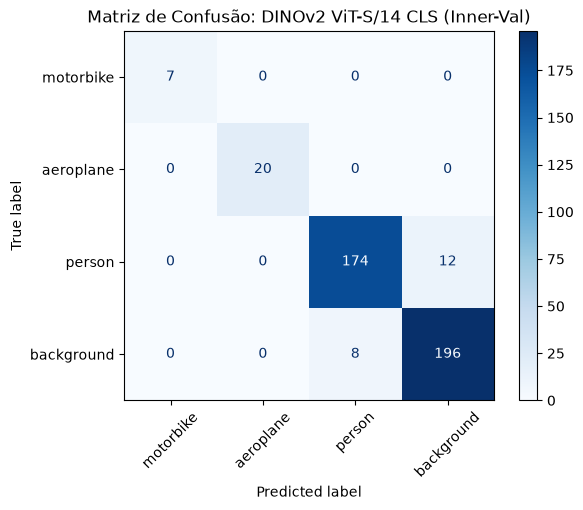

Accuracy Multiclasse: 0.9520
Macro-F1 Multiclasse: 0.9743


,Representação,Normalização,Dimensão,mAP (seed 42),Tempo Treino (s),Extração (ms/img),motorbike,aeroplane,person
0,DINOv2 ViT-S/14 CLS,l2,384,0.9921,0.0218,2.2145,0.9886,1.0,0.9877
1,DINOv2 CLS+patch-mean,l2,768,0.9961,0.0465,2.2145,0.9940,1.0,0.9942


In [21]:
def mc_dev_split(seed=42, val_size=0.2):
    lab, amb = {}, set()
    for c in CATEGORIES:
        for n in np.load(os.path.join(DATA_DIR, "encodings", BASE_ENC, f"{c}_train.npz"))["file_names"].tolist():
            if n in lab and lab[n] != c: amb.add(n)
            lab[n] = c
    for n in np.load(os.path.join(DATA_DIR, "encodings", BASE_ENC, f"background_train.npz"))["file_names"].tolist():
        if n in lab and lab[n] != "background": amb.add(n)
        lab.setdefault(n, "background")
    keep = sorted(n for n in lab if n not in amb)
    names, labels = np.array(keep), np.array([lab[n] for n in keep])
    
    sss = StratifiedShuffleSplit(n_splits=1, test_size=val_size, random_state=seed)
    idx_tr, idx_va = next(sss.split(names, labels))
    return names[idx_tr], labels[idx_tr], names[idx_va], labels[idx_va]

# -------------------------------------------------------------------------
# Avaliação Multiclasse DINOv2 na partição inner-val
# -------------------------------------------------------------------------
ntr_mc, ltr_mc, nva_mc, lva_mc = mc_dev_split()
Xtr_dino = l2_norm(rep_matrix("DINOv2 ViT-S/14 CLS", ntr_mc))
Xva_dino = l2_norm(rep_matrix("DINOv2 ViT-S/14 CLS", nva_mc))

clf_mc = LinearSVC(C=1.0, max_iter=5000, random_state=42)
clf_mc.fit(Xtr_dino, ltr_mc)
preds_mc = clf_mc.predict(Xva_dino)

cm = confusion_matrix(lva_mc, preds_mc, labels=CLASSES_MC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES_MC)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de Confusão: DINOv2 ViT-S/14 CLS (Inner-Val)")
plt.show()

print(f"Accuracy Multiclasse: {accuracy_score(lva_mc, preds_mc):.4f}")
print(f"Macro-F1 Multiclasse: {f1_score(lva_mc, preds_mc, average='macro'):.4f}")

# -------------------------------------------------------------------------
# Comparação CLS vs CLS + Patch Mean com AP por Classe e Tempos (como no Stage A)
# -------------------------------------------------------------------------

# Função auxiliar para recuperar o tempo de extração registrado
def get_extraction_time_per_img(tag="dinov2"):
    timings_path = os.path.join(FEAT_CACHE_DIR, "timings.json")
    if os.path.exists(timings_path):
        import json
        with open(timings_path, "r") as f:
            t_data = json.load(f)
            if tag in t_data and "ms_per_img_forward" in t_data[tag]:
                return t_data[tag]["ms_per_img_forward"]
    return None

dino_variants = ["DINOv2 ViT-S/14 CLS", "DINOv2 CLS+patch-mean"]
rows_dino = []
t_ext_ms = get_extraction_time_per_img("dinov2")

for v in dino_variants:
    # Cálculo do AP individual e do tempo de treino na seed 42
    cat_aps = {c: eval_dev_ap(v, c, "l2", seed=DEV_SEED, C=1.0)["ap"] for c in CATEGORIES}
    m_ap = np.mean(list(cat_aps.values()))
    t_train = np.mean([eval_dev_ap(v, c, "l2", seed=DEV_SEED, C=1.0)["t_train"] for c in CATEGORIES])
    dim = eval_dev_ap(v, CATEGORIES[0], "l2", seed=DEV_SEED, C=1.0)["dim"]
    
    row_dict = {
        "Representação": v,
        "Normalização": "l2",
        "Dimensão": dim,
        "mAP (seed 42)": m_ap,
        "Tempo Treino (s)": t_train,
    }
    if t_ext_ms is not None:
        row_dict["Extração (ms/img)"] = t_ext_ms
        
    row_dict.update(cat_aps)
    rows_dino.append(row_dict)

df_stageB = pd.DataFrame(rows_dino)
display(df_stageB.round(4))

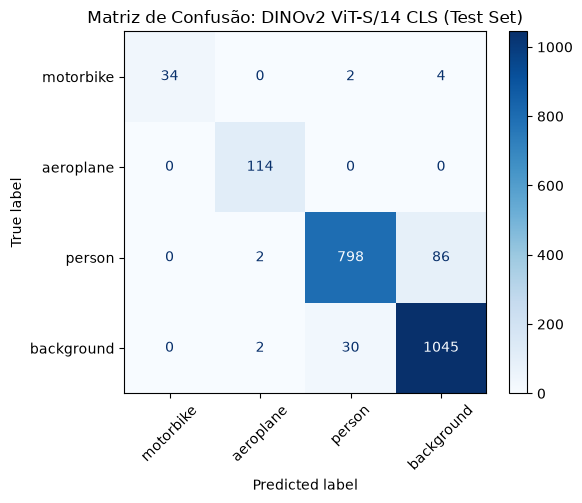

[Test Set] Accuracy Multiclasse: 0.9405
[Test Set] Macro-F1 Multiclasse: 0.9441


,Representação,Normalização,Dimensão,mAP (seed 42),Tempo Treino (s),Extração (ms/img),motorbike,aeroplane,person
0,DINOv2 ViT-S/14 CLS,l2,384,0.9921,0.0241,2.2145,0.9886,1.0,0.9877
1,DINOv2 CLS+patch-mean,l2,768,0.9961,0.0485,2.2145,0.9940,1.0,0.9942


In [23]:
# -------------------------------------------------------------------------
# 1. Função Genérica para Carregar Dados Multiclasse (Train ou Test)
# -------------------------------------------------------------------------
def load_multiclass_split(subset="train", val_size=0.2, seed=DEV_SEED, test_mode=False):
    """
    Carrega os dados descartando imagens com classes ambíguas.
    - Se test_mode=False: divide 'train' em 80% inner-train e 20% inner-val.
    - Se test_mode=True:  usa 100% de 'train' para treino e 'val' para teste final.
    """
    def get_clean_subset(sub):
        lab, amb = {}, set()
        for c in CATEGORIES:
            path = os.path.join(DATA_DIR, "encodings", BASE_ENC, f"{c}_{sub}.npz")
            for n in np.load(path)["file_names"].tolist():
                if n in lab and lab[n] != c:
                    amb.add(n)
                lab[n] = c
        bg_path = os.path.join(DATA_DIR, "encodings", BASE_ENC, f"background_{sub}.npz")
        for n in np.load(bg_path)["file_names"].tolist():
            if n in lab and lab[n] != "background":
                amb.add(n)
            lab.setdefault(n, "background")
        keep = sorted(n for n in lab if n not in amb)
        return np.array(keep), np.array([lab[n] for n in keep])

    if not test_mode:
        names_all, labels_all = get_clean_subset("train")
        sss = StratifiedShuffleSplit(n_splits=1, test_size=val_size, random_state=seed)
        idx_tr, idx_va = next(sss.split(names_all, labels_all))
        return names_all[idx_tr], labels_all[idx_tr], names_all[idx_va], labels_all[idx_va]
    else:
        names_tr, labels_tr = get_clean_subset("train")
        names_te, labels_te = get_clean_subset("val")
        return names_tr, labels_tr, names_te, labels_te


# -------------------------------------------------------------------------
# 2. Avaliação Multiclasse DINOv2 e Matrizes de Confusão
# -------------------------------------------------------------------------
# Escolha o modo de avaliação:
# use_test_set = False -> Inner-Val (diagnóstico do Stage B)
# use_test_set = True  -> Test Set (avaliação final para o relatório)
use_test_set = True 

ntr_mc, ltr_mc, neval_mc, leval_mc = load_multiclass_split(test_mode=use_test_set)
split_name = "Test Set" if use_test_set else "Inner-Val"

Xtr_dino = l2_norm(rep_matrix("DINOv2 ViT-S/14 CLS", ntr_mc))
Xeval_dino = l2_norm(rep_matrix("DINOv2 ViT-S/14 CLS", neval_mc))

# Treino do modelo LinearSVC (guardado globalmente como clf_mc)
clf_mc = LinearSVC(C=1.0, max_iter=5000, random_state=42)
clf_mc.fit(Xtr_dino, ltr_mc)
preds_mc = clf_mc.predict(Xeval_dino)

# Geração e visualização da Matriz de Confusão
cm = confusion_matrix(leval_mc, preds_mc, labels=CLASSES_MC)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES_MC)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title(f"Matriz de Confusão: DINOv2 ViT-S/14 CLS ({split_name})")
plt.tight_layout()
plt.show()

print(f"[{split_name}] Accuracy Multiclasse: {accuracy_score(leval_mc, preds_mc):.4f}")
print(f"[{split_name}] Macro-F1 Multiclasse: {f1_score(leval_mc, preds_mc, average='macro'):.4f}")


# -------------------------------------------------------------------------
# 3. Comparação CLS vs. CLS + Patch Mean (Tabela com AP por Classe e Tempos)
# -------------------------------------------------------------------------
def get_extraction_time_per_img(tag="dinov2"):
    timings_path = os.path.join(FEAT_CACHE_DIR, "timings.json")
    if os.path.exists(timings_path):
        import json
        with open(timings_path, "r") as f:
            t_data = json.load(f)
            if tag in t_data and "ms_per_img_forward" in t_data[tag]:
                return t_data[tag]["ms_per_img_forward"]
    return None

dino_variants = ["DINOv2 ViT-S/14 CLS", "DINOv2 CLS+patch-mean"]
rows_dino = []
t_ext_ms = get_extraction_time_per_img("dinov2")

for v in dino_variants:
    cat_aps = {c: eval_dev_ap(v, c, "l2", seed=DEV_SEED, C=1.0)["ap"] for c in CATEGORIES}
    m_ap = np.mean(list(cat_aps.values()))
    t_train = np.mean([eval_dev_ap(v, c, "l2", seed=DEV_SEED, C=1.0)["t_train"] for c in CATEGORIES])
    dim = eval_dev_ap(v, CATEGORIES[0], "l2", seed=DEV_SEED, C=1.0)["dim"]
    
    row_dict = {
        "Representação": v,
        "Normalização": "l2",
        "Dimensão": dim,
        "mAP (seed 42)": m_ap,
        "Tempo Treino (s)": t_train,
    }
    if t_ext_ms is not None:
        row_dict["Extração (ms/img)"] = t_ext_ms
        
    row_dict.update(cat_aps)
    rows_dino.append(row_dict)

df_stageB = pd.DataFrame(rows_dino)
display(df_stageB.round(4))

## 4. Stage C — Few-Shot Learning e Data Augmentation


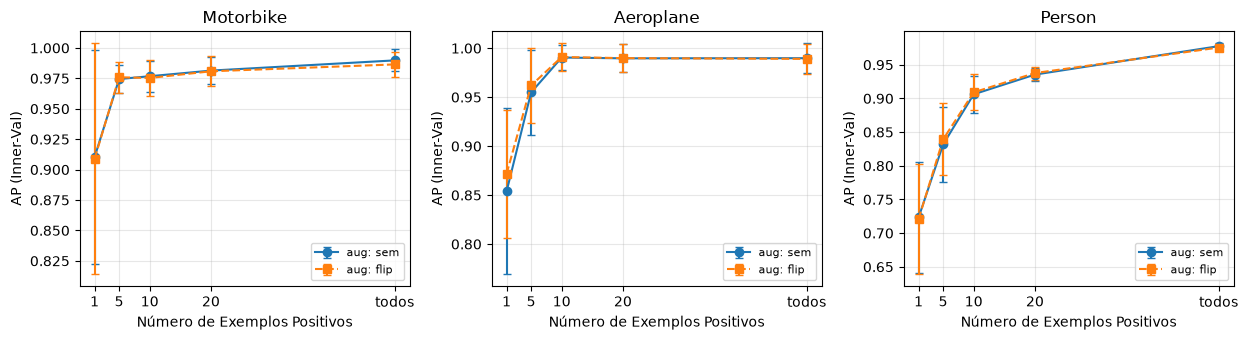

aug                sem   flip
category  n_pos              
motorbike 1      0.910  0.909
          5      0.974  0.976
          10     0.977  0.975
          20     0.981  0.981
          todos  0.990  0.986
aeroplane 1      0.854  0.872
          5      0.955  0.962
          10     0.990  0.991
          20     0.990  0.990
          todos  0.990  0.989
person    1      0.723  0.721
          5      0.832  0.839
          10     0.906  0.909
          20     0.935  0.938
          todos  0.978  0.976

In [36]:
FEWSHOT_REP = "DINOv2 ViT-S/14 CLS"
N_POS_LIST = (1, 5, 10, 20, None)  # None = todos os positivos disponíveis
N_NEG = 200
FEWSHOT_SEEDS = tuple(range(10))

def fewshot_ap(category, n_pos, flip_aug,seed=42, C=1.0):
    ntr, ytr, nva, yva = dev_split_names(category, seed=seed)
    rng = np.random.default_rng(1000 * seed + (n_pos or 0))
    pos, neg = np.where(ytr > 0)[0], np.where(ytr < 0)[0]
    if n_pos is not None:
        pos = rng.choice(pos, size=min(n_pos, len(pos)), replace=False)
    neg = rng.choice(neg, size=min(N_NEG, len(neg)), replace=False)
    
    sel = np.concatenate([pos, neg])
    names, y = ntr[sel], ytr[sel]
    
    X = rep_matrix(FEWSHOT_REP, names, flip=False)
    if flip_aug:
        X = np.vstack([X, rep_matrix(FEWSHOT_REP, names, flip=True)])
        y = np.concatenate([y, y])
        
    X_n = l2_norm(X)
    X_va_n = l2_norm(rep_matrix(FEWSHOT_REP, nva, flip=False))
    
    clf = LinearSVC(C=C, class_weight="balanced", max_iter=5000, random_state=seed)
    clf.fit(X_n, y)
    return average_precision_score(np.asarray(yva) > 0, clf.decision_function(X_va_n))

rows_fewshot = []
for cat in CATEGORIES:
    for n_pos in N_POS_LIST:
        for aug in (False, True):
            aps = [fewshot_ap(cat, n_pos, aug,s) for s in FEWSHOT_SEEDS]
            rows_fewshot.append({
                "category": cat,
                "n_pos": str(n_pos) if n_pos is not None else "todos",
                "aug": "flip" if aug else "sem",
                "ap_mean": np.mean(aps),
                "ap_std": np.std(aps)
            })

df_fewshot = pd.DataFrame(rows_fewshot)

# Gráficos Few-Shot com barras de erro
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(4.2 * len(CATEGORIES), 3.5), squeeze=False)
for ax, cat in zip(axes[0], CATEGORIES):
    for aug, mk in [("sem", "o-"), ("flip", "s--")]:
        d = df_fewshot[(df_fewshot.category == cat) & (df_fewshot.aug == aug)]
        xs = [1, 5, 10, 20, 50]  # posições fixas no gráfico
        ax.errorbar(xs, d.ap_mean, yerr=d.ap_std, fmt=mk, capsize=3, label=f"aug: {aug}")
    ax.set_title(cat.capitalize())
    ax.set_xlabel("Número de Exemplos Positivos")
    ax.set_xticks([1, 5, 10, 20, 50])
    ax.set_xticklabels(["1", "5", "10", "20", "todos"])
    ax.set_ylabel("AP (Inner-Val)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

display(df_fewshot.pivot_table(index=["category", "n_pos"], columns="aug", values="ap_mean", sort=False).round(3))

## 4. Stage D — Hyperparameter Selection (Afinação de C no SVM)


,rep,norm,C,mAP_val,mAP_val_std,mAP_train
0,ResNet18 layer4.1,l2,0.1,0.971868,0.002126,0.981812
1,ResNet18 layer4.1,l2,1.0,0.975516,0.000233,0.997216
2,ResNet18 layer4.1,l2,10.0,0.972188,0.001577,0.999732
3,ResNet18 layer4.1,l2,100.0,0.962352,0.003029,1.000000
4,ResNet18 layer4.1,l2,1000.0,0.964271,0.002335,1.000000
5,ResNet18 layer4.1,std,0.1,0.971441,0.001334,0.989807
6,ResNet18 layer4.1,std,1.0,0.973818,0.001443,0.998677
7,ResNet18 layer4.1,std,10.0,0.963313,0.001307,0.999967
8,ResNet18 layer4.1,std,100.0,0.959035,0.001468,1.000000
9,ResNet18 layer4.1,std,1000.0,0.960036,0.000499,1.000000


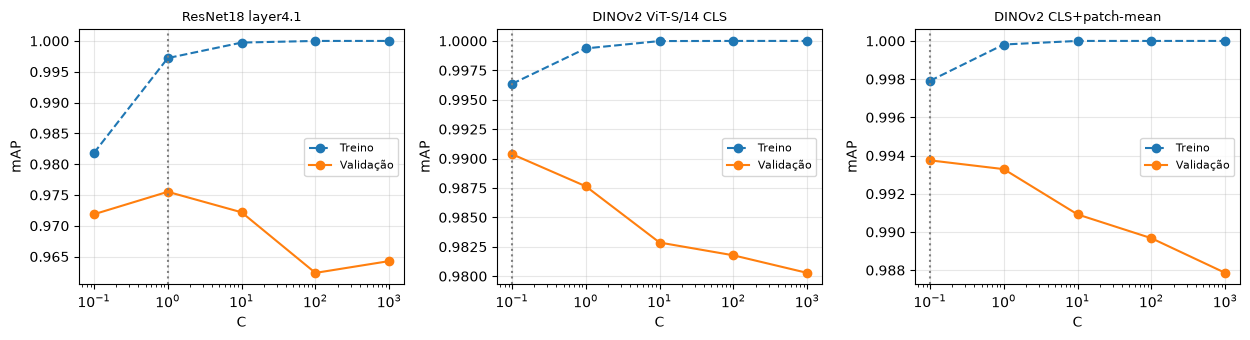

In [44]:
C_GRID = (0.1, 1, 10, 100, 1000)
FINAL_REPS = ["ResNet18 layer4.1", "DINOv2 ViT-S/14 CLS", "DINOv2 CLS+patch-mean"]

rows_stageD = []
for rep in FINAL_REPS:
    for norm in ["l2", "std"]:
        for C in C_GRID:
            per_seed_val = []
            per_seed_tr = []
            for s in SEEDS:
                cat_val = []
                cat_tr = []
                for cat in CATEGORIES:
                    ntr, ytr, nva, yva = dev_split_names(cat, seed=s)
                    Xtr = rep_matrix(rep, ntr)
                    Xva = rep_matrix(rep, nva)
                    
                    fn = fit_norm(Xtr, norm)
                    Xtr_n = fn(Xtr)
                    Xva_n = fn(Xva)
                    
                    clf = LinearSVC(C=C, max_iter=5000, random_state=s).fit(Xtr_n, ytr)
                    
                    # AP no Treino
                    score_tr = clf.decision_function(Xtr_n)
                    cat_tr.append(average_precision_score(np.asarray(ytr) > 0, score_tr))
                    
                    # AP na Validação
                    score_va = clf.decision_function(Xva_n)
                    cat_val.append(average_precision_score(np.asarray(yva) > 0, score_va))
                
                per_seed_val.append(np.mean(cat_val))
                per_seed_tr.append(np.mean(cat_tr))
                
            rows_stageD.append({
                "rep": rep,
                "norm": norm,
                "C": C,
                "mAP_val": np.mean(per_seed_val),
                "mAP_val_std": np.std(per_seed_val),
                "mAP_train": np.mean(per_seed_tr)
            })

df_stageD = pd.DataFrame(rows_stageD)

# Seleção da melhor configuração para cada representação
best_configs = {}
for rep in FINAL_REPS:
    best = df_stageD[df_stageD.rep == rep].sort_values("mAP_val", ascending=False).iloc[0]
    best_configs[rep] = {"norm": best.norm, "C": best.C, "mAP_val": best.mAP_val}

#display(pd.DataFrame(best_configs).T.round(4))
display(df_stageD)

# Gráficos de treino vs validação
fig, axes = plt.subplots(1, len(FINAL_REPS), figsize=(4.2 * len(FINAL_REPS), 3.5), squeeze=False)
for ax, rep in zip(axes[0], FINAL_REPS):
    best_n = best_configs[rep]["norm"]
    d = df_stageD[(df_stageD.rep == rep) & (df_stageD.norm == best_n)]
    ax.plot(d.C, d.mAP_train, "o--", label="Treino")
    ax.plot(d.C, d.mAP_val, "o-", label="Validação")
    ax.axvline(best_configs[rep]["C"], color="gray", ls=":")
    ax.set_xscale("log")
    ax.set_title(rep, fontsize=9)
    ax.set_xlabel("C")
    ax.set_ylabel("mAP")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [40]:
# -------------------------------------------------------------------------
# Avaliação Oficial no Conjunto de Teste (val.npz) com as Melhores Configurações
# -------------------------------------------------------------------------
def eval_final_test(rep, norm_type, C):
    """Treina com o conjunto de treino completo e avalia no teste (val.npz)."""
    cat_aps = {}
    t_train_list = []
    
    for cat in CATEGORIES:
        # 1. Carregar nomes de ficheiro completos
        ntr, ytr = load_names(cat, subset="train")
        nte, yte = load_names(cat, subset="val")
        
        # 2. Obter as matrizes de características
        Xtr = rep_matrix(rep, ntr)
        Xte = rep_matrix(rep, nte)
        
        # 3. Ajustar normalizador APENAS nos dados de treino
        fn = fit_norm(Xtr, norm_type)
        Xtr_n = fn(Xtr)
        Xte_n = fn(Xte)
        
        # 4. Treinar LinearSVC
        t0 = time.perf_counter()
        clf = LinearSVC(C=C, max_iter=5000, random_state=42)
        clf.fit(Xtr_n, ytr)
        t_train_list.append(time.perf_counter() - t0)
        
        # 5. Avaliação de AP contínuo no teste
        scores = clf.decision_function(Xte_n)
        cat_aps[cat] = average_precision_score(np.asarray(yte) > 0, scores)
        
    dim = Xtr.shape[1]
    m_ap = np.mean(list(cat_aps.values()))
    t_train = np.mean(t_train_list)
    
    return {
        "Representação": rep,
        "Norm.": norm_type,
        "C": C,
        "Dim.": dim,
        "mAP (Teste)": m_ap,
        "Moto": cat_aps["motorbike"],
        "Aero": cat_aps["aeroplane"],
        "Pess.": cat_aps["person"],
        "Treino (s)": t_train
    }

# Executa para as 4 representações com os hiperparâmetros de best_configs
rows_final_test = []
for rep in FINAL_REPS:
    cfg = best_configs[rep]
    res = eval_final_test(rep=rep, norm_type=cfg["norm"], C=cfg["C"])
    rows_final_test.append(res)

df_final_test = pd.DataFrame(rows_final_test)
display(df_final_test.round(4))

,Representação,Norm.,C,Dim.,mAP (Teste),Moto,Aero,Pess.,Treino (s)
0,ResNet18 layer4.1,l2,1.0,512,0.9804,0.9843,0.9805,0.9763,0.0658
1,DINOv2 ViT-S/14 CLS,std,0.1,384,0.9876,0.9818,1.0000,0.9811,0.0352
2,DINOv2 CLS+patch-mean,std,0.1,768,0.9922,0.9881,1.0000,0.9886,0.0647


## 4. Stage E — CLIP Zero-Shot Classification


In [60]:
TEMPLATES = [
   'a photo of a {}.',
    'a blurry photo of a {}.',
    "a picture of a {}.",
    "an image containing a {}.",
    "a close-up photo of a {}.",
    'a low contrast photo of a {}.',
    'a high contrast photo of a {}.',
    'a bad photo of a {}.',
    'a good photo of a {}.',
]

# Templates adaptados ao contexto real de cada classe
PROMPTS_CONTEXTUAIS = {
    "motorbike": [
        "a photo of a motorbike.",
        "a photo of a motorcycle.",
        "a motorcycle parked on the street.",
        "a photo of a motorbike on the road.",
        "a side view of a motorbike.",
        "a person riding a motorcycle."
    ],
    "aeroplane": [
        "a photo of an aeroplane.",
        "a photo of an airplane.",
        "an airplane flying in the sky.",
        "a large aeroplane on the runway.",
        "an airplane parked at an airport.",
        "a side view of an aeroplane."
    ],
    "person": [
        "a photo of a person.",
        "a photo of a human.",
        "a portrait photo of a person.",
        "a photo of a person standing.",
        "a person walking outdoors.",
        "a close-up photo of a person."
    ],
    "background": [
        "a photo of an empty scene.",
        "a landscape without people or vehicles.",
        "an indoor room with furniture.",
        "a photo of architecture and buildings.",
        "a photo of nature, trees and grass.",
        "a random object or textured pattern."
    ]
}

CLASS_SYNONYMS = {
    "motorbike": ["motorbike", "motorcycle"],
    "aeroplane": ["aeroplane", "airplane"],
    "person": [
        "person", 
        "people", 
        "man", 
        "woman", 
        "child", 
        "human being",
        "pedestrian"
    ],
    "background": [
    "a photo of an empty scene", "a random object", 
    "a picture of nature", "animals", "textures and patterns"
]
}

PROMPT_SETS = {
    "P1 simples ('a photo of a X')": (["a photo of a {}."], 1),
    "P2 só a palavra da classe":     (["{}"], 1),
    "P3 sinónimos (1 template)":     (["a photo of a {}."], None),
    "P4 9 templates genéricos":       (TEMPLATES, 1),
    "P5 9 templates + sinónimos":    (TEMPLATES, None),
    "P6 templates contextuais (B)":  (PROMPTS_CONTEXTUAIS, None),
}

def encode_prompts_for_classes(model_clip, prompt_set_key):
    tpls_or_dict, nn_val = PROMPT_SETS[prompt_set_key]
    text_embs = []
    
    for cls in CLASSES_MC:
        # Se for um dicionário de frases prontas (caso do P6)
        if isinstance(tpls_or_dict, dict):
            phrases = tpls_or_dict[cls]
        else:
            tpls = tpls_or_dict
            syns = CLASS_SYNONYMS[cls] if nn_val is None else CLASS_SYNONYMS[cls][:nn_val]
            phrases = [t.format(n) for t in tpls for n in syns]
            
        toks = clip.tokenize(phrases).to(DEVICE)
        with torch.inference_mode():
            t_f = model_clip.encode_text(toks).float()
            t_f = t_f / t_f.norm(dim=-1, keepdim=True)
            mean_t = t_f.mean(dim=0)
            mean_t = mean_t / mean_t.norm()
            text_embs.append(mean_t.cpu().numpy())
            
    return np.stack(text_embs)  # (4, 512)


"""
PROMPT_SETS = {
    "P1 simples ('a photo of a X')": (["a photo of a {}."], 1),
    "P2 só a palavra da classe":     (["{}"], 1),
    "P3 sinónimos (1 template)":     (["a photo of a {}."], None),
    "P4 5 templates (1 nome)":       (TEMPLATES, 1),
    "P5 5 templates + sinónimos":    (TEMPLATES, None),
}"""


# Avaliação Multiclasse Zero-Shot em Inner-Val (Seed 0)
model_clip, _ = getModel("clip_vit_b_32", device=DEVICE)
ntr_mc, ltr_mc, nva_mc, lva_mc = mc_dev_split(seed=42)
clip_img_va = rep_matrix("CLIP ViT-B/32 image", nva_mc)
clip_img_va = l2_norm(clip_img_va)
rows_clip_eval = []
for p_name in PROMPT_SETS:
    W_text = encode_prompts_for_classes(model_clip, p_name)  # (4, 512)
    logits = clip_img_va @ W_text.T                         # similaridade cosseno (N, 4)
    preds_idx = np.argmax(logits, axis=1)
    preds_cls = np.array([CLASSES_MC[i] for i in preds_idx])
    
    # 1. Métricas Multiclasse Discretas
    acc = accuracy_score(lva_mc, preds_cls)
    macro_f1 = f1_score(lva_mc, preds_cls, average="macro", zero_division=0)
    
    # 2. Cálculo do AP contínuo por classe
    cat_aps = {}
    for idx, cat in enumerate(CLASSES_MC):
        y_true_binary = (np.asarray(lva_mc) == cat).astype(int)
        scores_cat = logits[:, idx]  # logits/similaridade para a classe correspondente
        cat_aps[cat] = average_precision_score(y_true_binary, scores_cat)
        
    # mAP sobre as três categorias de interesse (excluindo background)
    target_cats = [c for c in CLASSES_MC if c != "background"]
    m_ap = np.mean([cat_aps[c] for c in target_cats])
    
    entry = {
        "Conjunto de Prompts": p_name,
        "Accuracy": acc,
        "Macro F1": macro_f1,
        "mAP": m_ap
    }
    # Adiciona o AP individual de cada classe
    for cat in CLASSES_MC:
        entry[f"AP_{cat}"] = cat_aps[cat]
        
    rows_clip_eval.append(entry)

df_clip = pd.DataFrame(rows_clip_eval)
display(df_clip.round(4))

,Conjunto de Prompts,Accuracy,Macro F1,mAP,AP_motorbike,AP_aeroplane,AP_person,AP_background
0,P1 simples ('a photo of a X'),0.4844,0.4377,0.8234,0.9379,0.9452,0.5871,0.5903
1,P2 só a palavra da classe,0.5036,0.4512,0.8185,0.9123,0.9495,0.5936,0.6760
2,P3 sinónimos (1 template),0.6835,0.6490,0.8105,0.9379,0.9474,0.5461,0.7610
3,P4 9 templates genéricos,0.5612,0.5178,0.8526,1.0000,0.9868,0.5709,0.6342
4,P5 9 templates + sinónimos,0.7218,0.6890,0.8452,1.0000,0.9897,0.5459,0.7913
5,P6 templates contextuais (B),0.5971,0.6038,0.8179,0.9617,0.9474,0.5445,0.6849


A avaliar a configuração escolhida: P5 9 templates + sinónimos

=== Relatório de Classificação por Classe ===
              precision    recall  f1-score   support

   aeroplane     0.7692    1.0000    0.8696        20
  background     0.8312    0.6275    0.7151       204
   motorbike     0.2800    1.0000    0.4375         7
      person     0.6887    0.7849    0.7337       186

    accuracy                         0.7218       417
   macro avg     0.6423    0.8531    0.6890       417
weighted avg     0.7554    0.7218    0.7261       417



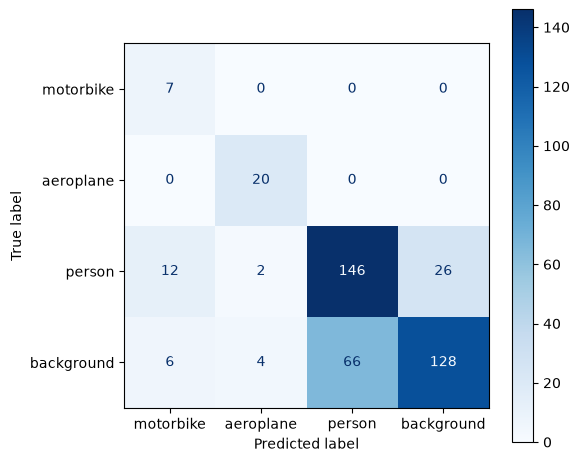

=== Resultados de Class-wise Retrieval (AP / mAP) ===
AP (motorbike ): 1.0000
AP (aeroplane ): 0.9897
AP (person    ): 0.5459
AP (background): 0.7913
----------------------------------------
mAP (Target Classes: Moto, Aero, Person): 0.8452
mAP (Global com Background):              0.8317


In [62]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# Avaliação Completa do Melhor Modelo Zero-Shot (CLIP com P5)
# -------------------------------------------------------------------------

best_prompt = df_clip.sort_values("Macro F1", ascending=False).iloc[0]["Conjunto de Prompts"]

# 1. Obter os embeddings textuais para o melhor conjunto selecionado (P5)
print(f"A avaliar a configuração escolhida: {best_prompt}\n")
W_text_best = encode_prompts_for_classes(model_clip, best_prompt)  # (4, 512)

# Similaridade cosseno (N, 4)
logits_best = clip_img_va @ W_text_best.T

# 2. Predição da categoria com maior similaridade (argmax)
preds_idx = np.argmax(logits_best, axis=1)
preds_cls = np.array([CLASSES_MC[i] for i in preds_idx])

# 3. Métricas por classe (Precision, Recall, F1-Score)
print("=== Relatório de Classificação por Classe ===")
print(classification_report(lva_mc, preds_cls, digits=4, zero_division=0))

# 4. Matriz de Confusão
cm = confusion_matrix(lva_mc, preds_cls, labels=CLASSES_MC)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES_MC)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.tight_layout()
plt.show()

# 5. Class-wise Retrieval: Ordenação por similaridade e cálculo de AP/mAP
print("=== Resultados de Class-wise Retrieval (AP / mAP) ===")
cat_aps = {}
target_classes = [c for c in CLASSES_MC if c != "background"]

for idx, cat in enumerate(CLASSES_MC):
    # Rótulo binário de verdade fundamental (1 se for a classe, 0 caso contrário)
    y_true_binary = (np.asarray(lva_mc) == cat).astype(int)
    scores_cat = logits_best[:, idx]
    
    # AP contínuo derivado do ranking de similaridade
    ap = average_precision_score(y_true_binary, scores_cat)
    cat_aps[cat] = ap
    print(f"AP ({cat:10s}): {ap:.4f}")

mAP_target = np.mean([cat_aps[c] for c in target_classes])
mAP_all = np.mean(list(cat_aps.values()))

print("-" * 40)
print(f"mAP (Target Classes: Moto, Aero, Person): {mAP_target:.4f}")
print(f"mAP (Global com Background):              {mAP_all:.4f}")

=== Relatório de Classificação no Teste ===
              precision    recall  f1-score   support

   aeroplane     0.7308    1.0000    0.8444       114
  background     0.8516    0.6128    0.7127      1077
   motorbike     0.2635    0.9750    0.4149        40
      person     0.6715    0.7867    0.7245       886

    accuracy                         0.7133      2117
   macro avg     0.6293    0.8436    0.6742      2117
weighted avg     0.7586    0.7133    0.7191      2117



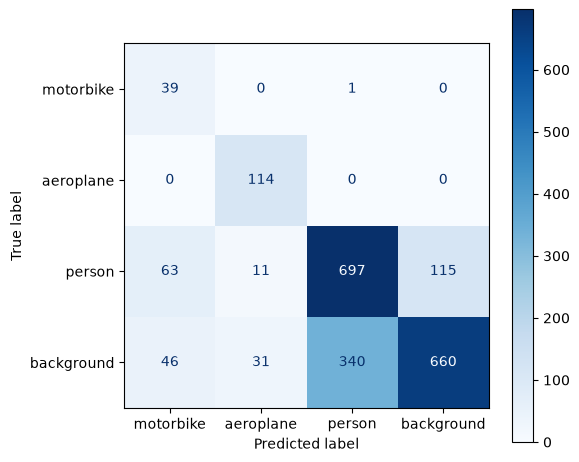

=== Resultados de Class-wise Retrieval no Teste (AP / mAP) ===
AP (motorbike ): 0.9020
AP (aeroplane ): 0.9801
AP (person    ): 0.5321
AP (background): 0.7770
----------------------------------------
mAP (Target Classes: Moto, Aero, Person): 0.8047
mAP (Global com Background):              0.7978


In [91]:
# -------------------------------------------------------------------------
# Avaliação no CONJUNTO DE TESTE (test_mode=True carrega o split 'val.npz')
# -------------------------------------------------------------------------
# 1. Carregar as imagens e rótulos de teste oficial
_, _, n_test, l_test = load_multiclass_split(test_mode=True)

# 2. Obter as características CLIP do conjunto de teste com L2 norm
clip_img_test = l2_norm(rep_matrix("CLIP ViT-B/32 image", n_test))

# 3. Similaridade cosseno contra o conjunto de teste
logits_test = clip_img_test @ W_text_best.T

# 4. Predições
preds_idx = np.argmax(logits_test, axis=1)
preds_cls = np.array([CLASSES_MC[i] for i in preds_idx])

# 5. Relatório e Matriz de Confusão no Teste
print("=== Relatório de Classificação no Teste ===")
print(classification_report(l_test, preds_cls, digits=4, zero_division=0))

cm = confusion_matrix(l_test, preds_cls, labels=CLASSES_MC)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES_MC)
disp.plot(cmap="Blues", values_format="d", ax=ax)
plt.tight_layout()
plt.show()

# 6. Class-wise Retrieval no Teste
print("=== Resultados de Class-wise Retrieval no Teste (AP / mAP) ===")
cat_aps = {}
target_classes = [c for c in CLASSES_MC if c != "background"]

for idx, cat in enumerate(CLASSES_MC):
    y_true_binary = (np.asarray(l_test) == cat).astype(int)
    scores_cat = logits_test[:, idx]
    ap = average_precision_score(y_true_binary, scores_cat)
    cat_aps[cat] = ap
    print(f"AP ({cat:10s}): {ap:.4f}")

mAP_target = np.mean([cat_aps[c] for c in target_classes])
mAP_all = np.mean(list(cat_aps.values()))

print("-" * 40)
print(f"mAP (Target Classes: Moto, Aero, Person): {mAP_target:.4f}")
print(f"mAP (Global com Background):              {mAP_all:.4f}")

## 4. Stage F — Análise Visual e Casos de Falha 


In [64]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.svm import LinearSVC

# 1. Carregar split e treinar o classificador LinearSVC sobre a ResNet-18 (layer4.1)
ntr, ytr, nva, yva = dev_split_names("motorbike", seed=42)
Xtr = l2_norm(rep_matrix("ResNet18 layer4.1", ntr))
Xva = l2_norm(rep_matrix("ResNet18 layer4.1", nva))

clf = LinearSVC(C=1.0, max_iter=5000, random_state=42).fit(Xtr, ytr)
scores_va = clf.decision_function(Xva)
preds_va = np.where(scores_va > 0, 1, -1)

# 2. Identificar índices dos casos típicos
tp_idxs = np.where((yva == 1) & (preds_va == 1))[0]
fp_idxs = np.where((yva == -1) & (preds_va == 1))[0]
fn_idxs = np.where((yva == 1) & (preds_va == -1))[0]

# Selecionar as amostras mais representativas com base no score
sample_tp = nva[tp_idxs[np.argmax(scores_va[tp_idxs])]]  # Maior convicção de acerto
sample_fp = nva[fp_idxs[np.argmax(scores_va[fp_idxs])]]  # Maior erro falso positivo
sample_fn = nva[fn_idxs[np.argmin(scores_va[fn_idxs])]]  # Pior omissão (falso negativo)

print(f"Sucesso (TP):        {sample_tp}")
print(f"Falso Positivo (FP): {sample_fp}")
print(f"Falso Negativo (FN): {sample_fn}")

Sucesso (TP):        009209
Falso Positivo (FP): 006635
Falso Negativo (FN): 000770


In [68]:
import torchvision.transforms as T
import clip

# -------------------------------------------------------------------------
# A. ResNet-18: Class Activation Mapping (CAM) na camada layer4.1
# -------------------------------------------------------------------------
model_resnet, preprocess_resnet = getModel("resnet18", device=DEVICE, nofc=False)
extractor_resnet = IntermediateFeatureExtractor(model_resnet)
w_resnet = clf.coef_.ravel()  # Pesos do classificador linear

def compute_resnet_cam(img_path, model, w_clf):
    model.eval()
    img_pil = Image.open(img_path).convert("RGB")
    tensor = preprocess_resnet(img_pil).unsqueeze(0).to(DEVICE)
    
    _, inter = extractor_resnet(tensor)
    act = inter["layer4.1"].squeeze(0).cpu().numpy()  # (512, H, W)
    
    cam = np.zeros(act.shape[1:], dtype=np.float32)
    for i, w in enumerate(w_clf):
        cam += w * act[i, :, :]
    cam = np.maximum(cam, 0)  # ReLU
    cam = cam / (np.max(cam) + 1e-10)
    return img_pil, cam

# -------------------------------------------------------------------------
# B. DINOv2: Mapa de Similaridade de Patches com o Hiperplano do SVM
# -------------------------------------------------------------------------
model_dino, _ = getModel("dinov2_vits14", device=DEVICE)
Xtr_dino = l2_norm(rep_matrix("DINOv2 ViT-S/14 CLS", ntr))
clf_dino = LinearSVC(C=1.0, max_iter=5000, random_state=42).fit(Xtr_dino, ytr)
w_dino = clf_dino.coef_.ravel()

def compute_dino_map(img_path, model, w_clf):
    model.eval()
    img_pil = Image.open(img_path).convert("RGB")
    w, h = img_pil.size
    new_w, new_h = (w // 14) * 14, (h // 14) * 14
    img_resized = img_pil.resize((new_w, new_h))
    
    preprocess = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    tensor = preprocess(img_resized).unsqueeze(0).to(DEVICE)
    
    with torch.inference_mode():
        # Extrai os tokens de patch da última camada
        ret = model.get_intermediate_layers(tensor, n=1, return_class_token=True)
        patch_tokens = ret[0][0].squeeze(0).cpu().numpy()  # (N_patches, 384)
        
    patch_scores = patch_tokens @ w_clf
    cam_dino = patch_scores.reshape(new_h // 14, new_w // 14)
    cam_dino = np.maximum(cam_dino, 0)
    cam_dino = cam_dino / (np.max(cam_dino) + 1e-10)
    return img_pil, cam_dino

# -------------------------------------------------------------------------
# C. CLIP (ViT-B/32): Projeção Espacial Patch-to-Text
# -------------------------------------------------------------------------
model_clip, clip_preprocess = getModel("clip_vit_b_32", device=DEVICE)

def compute_clip_map(img_path, model, prompt="a photo of a motorbike."):
    model.eval()
    img_pil = Image.open(img_path).convert("RGB")
    tensor = clip_preprocess(img_pil).unsqueeze(0).to(DEVICE)
    
    # Converte o tensor de entrada para o mesmo dtype dos pesos do CLIP (float16 em GPU ou float32 em CPU)
    target_dtype = model.visual.conv1.weight.dtype
    tensor = tensor.to(target_dtype)
    
    toks = clip.tokenize([prompt]).to(DEVICE)
    with torch.inference_mode():
        text_emb = model.encode_text(toks)
        text_emb = text_emb / text_emb.norm(dim=-1, keepdim=True)
        
        # Projeção convolucional de entrada dos patches
        x = model.visual.conv1(tensor)  # (1, width, grid, grid)
        grid_h, grid_w = x.shape[2], x.shape[3]
        x = x.reshape(x.shape[0], x.shape[1], -1).permute(0, 2, 1)
        
        # Adicionar o token de classe e posições
        cls_token = model.visual.class_embedding.to(target_dtype) + torch.zeros(
            x.shape[0], 1, x.shape[-1], dtype=target_dtype, device=x.device
        )
        x = torch.cat([cls_token, x], dim=1)
        x = x + model.visual.positional_embedding.to(target_dtype)
        x = model.visual.ln_pre(x)
        x = x.permute(1, 0, 2)
        x = model.visual.transformer(x)
        x = x.permute(1, 0, 2)
        
        # Projeção para o espaço latente multimodal
        patch_feats = x[:, 1:, :] @ model.visual.proj
        patch_feats = patch_feats / patch_feats.norm(dim=-1, keepdim=True)
        
        sim = (patch_feats @ text_emb.T).squeeze().float().cpu().numpy()
        
    cam_clip = sim.reshape(grid_h, grid_w)
    cam_clip = np.maximum(cam_clip, 0)
    cam_clip = cam_clip / (np.max(cam_clip) + 1e-10)
    return img_pil, cam_clip

Using cache found in C:\Users\Henrique/.cache\torch\hub\facebookresearch_dinov2_main


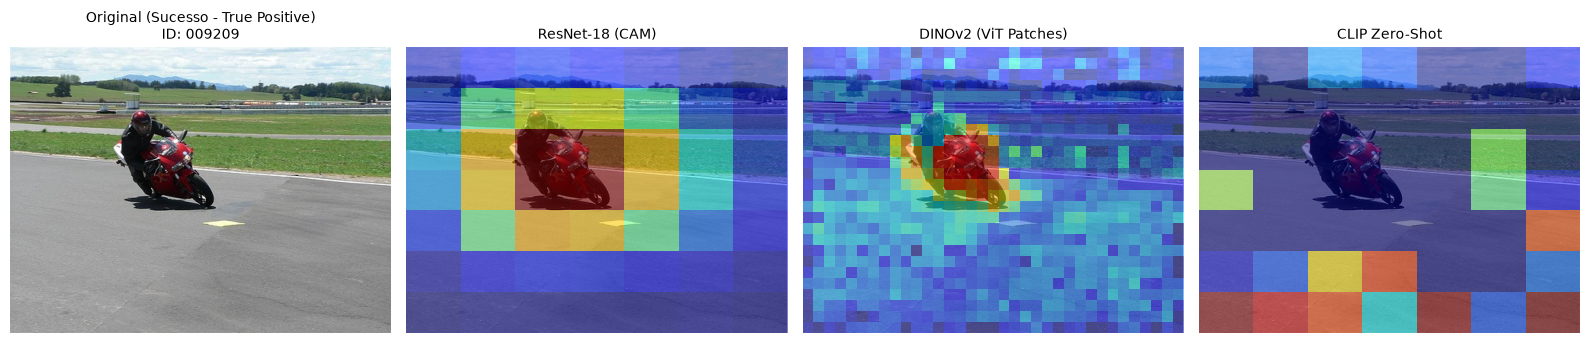

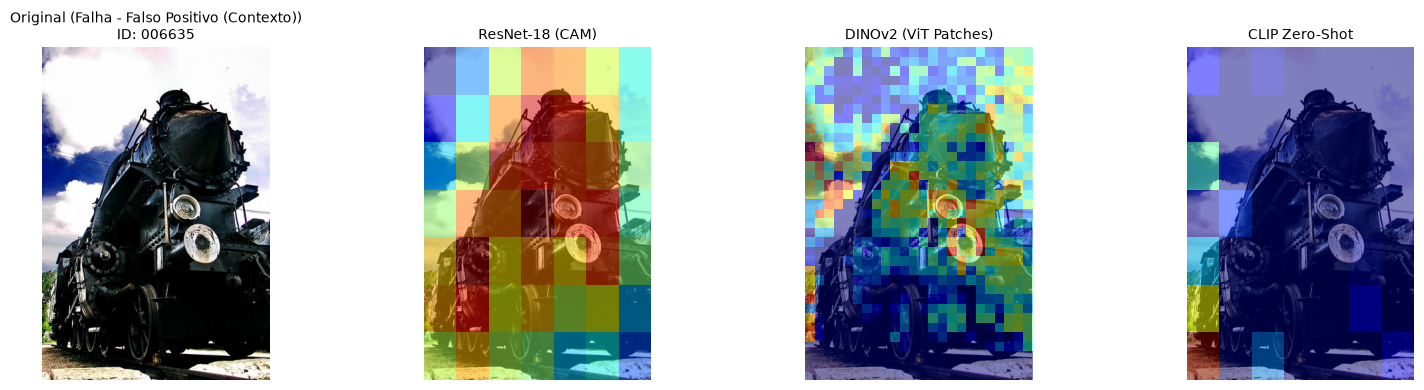

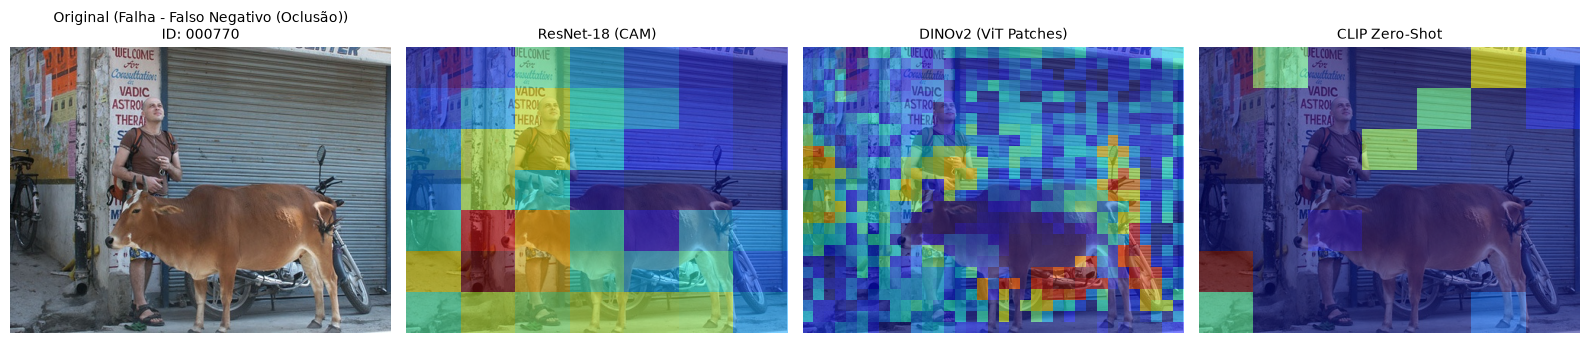

In [69]:
def plot_comparison(sample_name, case_title, file_name=None):
    img_path = os.path.join(IMAGES_DIR, f"{sample_name}.jpg")
    if not os.path.exists(img_path):
        print(f"Imagem {img_path} não encontrada.")
        return

    img_pil, cam_res = compute_resnet_cam(img_path, model_resnet, w_resnet)
    _, cam_dino = compute_dino_map(img_path, model_dino, w_dino)
    _, cam_clip = compute_clip_map(img_path, model_clip, prompt="a photo of a motorbike.")

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    # 1. Imagem Original
    axes[0].imshow(img_pil)
    axes[0].set_title(f"Original ({case_title})\nID: {sample_name}", fontsize=10)
    axes[0].axis("off")
    
    # 2. ResNet-18 CAM
    axes[1].imshow(img_pil)
    axes[1].imshow(cam_res, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[1].set_title("ResNet-18 (CAM)", fontsize=10)
    axes[1].axis("off")
    
    # 3. DINOv2 Patches
    axes[2].imshow(img_pil)
    axes[2].imshow(cam_dino, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[2].set_title("DINOv2 (ViT Patches)", fontsize=10)
    axes[2].axis("off")
    
    # 4. CLIP Patch-to-Text
    axes[3].imshow(img_pil)
    axes[3].imshow(cam_clip, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[3].set_title("CLIP Zero-Shot", fontsize=10)
    axes[3].axis("off")
    
    plt.tight_layout()
    if file_name:
        plt.savefig(file_name, dpi=200, bbox_inches="tight")
    plt.show()

# Gerar figuras para Sucesso (TP) e Falha (FP ou FN)
plot_comparison(sample_tp, "Sucesso - True Positive", file_name="stageF_sucesso.png")
plot_comparison(sample_fp, "Falha - Falso Positivo (Contexto)", file_name="stageF_falha_fp.png")
plot_comparison(sample_fn, "Falha - Falso Negativo (Oclusão)", file_name="stageF_falha_fn.png")

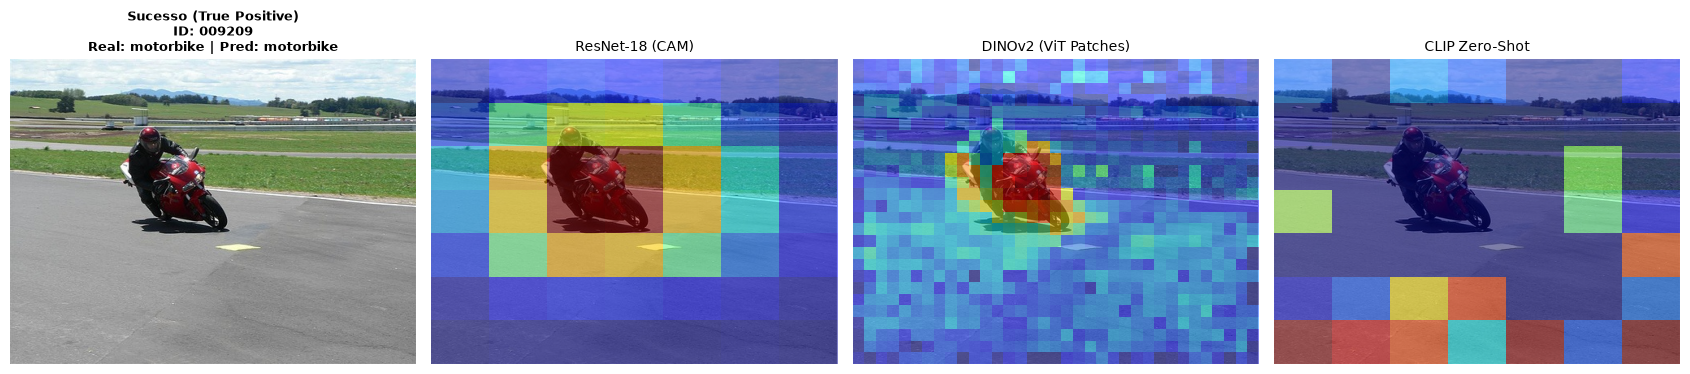

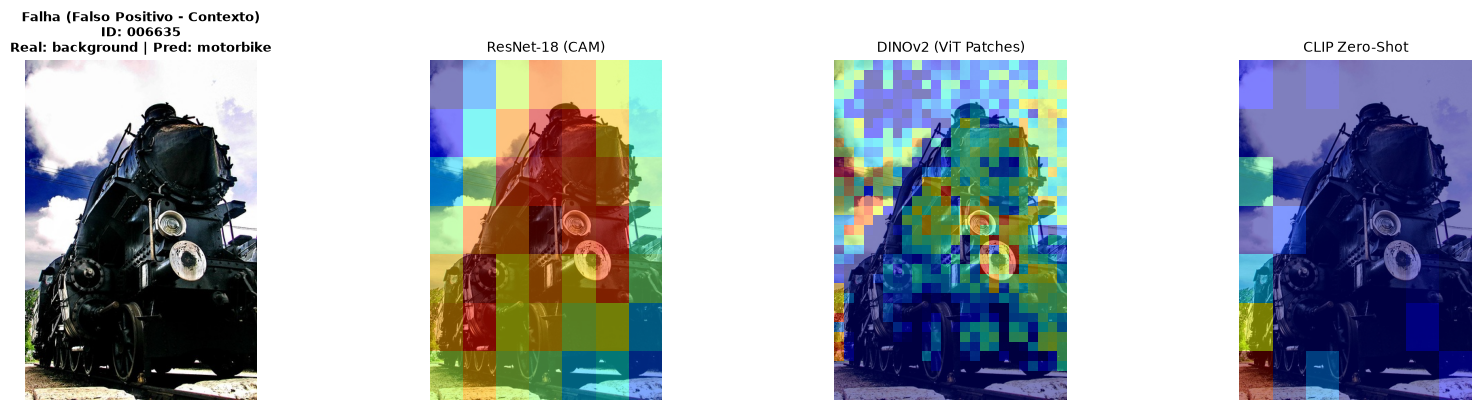

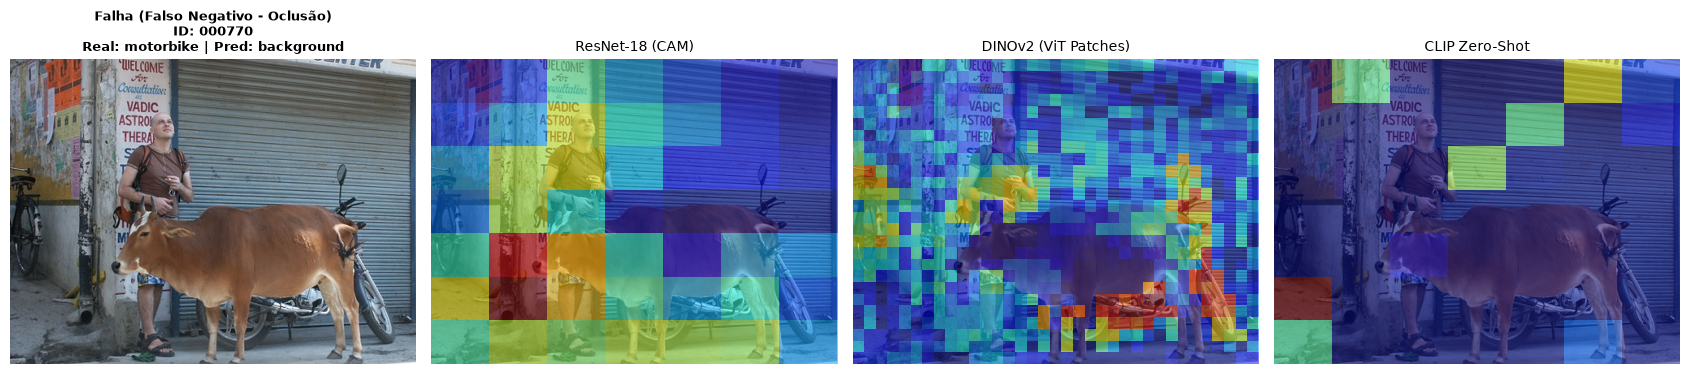

In [70]:
def get_class_name(y_val):
    return "motorbike" if y_val == 1 else "background"

def plot_comparison(sample_name, case_title, true_label, pred_label, file_name=None):
    img_path = os.path.join(IMAGES_DIR, f"{sample_name}.jpg")
    if not os.path.exists(img_path):
        print(f"Imagem {img_path} não encontrada.")
        return

    img_pil, cam_res = compute_resnet_cam(img_path, model_resnet, w_resnet)
    _, cam_dino = compute_dino_map(img_path, model_dino, w_dino)
    _, cam_clip = compute_clip_map(img_path, model_clip, prompt="a photo of a motorbike.")

    fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
    
    # 1. Imagem Original com ID, Classe Real e Predição
    axes[0].imshow(img_pil)
    title_text = (
        f"{case_title}\n"
        f"ID: {sample_name}\n"
        f"Real: {true_label} | Pred: {pred_label}"
    )
    axes[0].set_title(title_text, fontsize=9, fontweight="bold")
    axes[0].axis("off")
    
    # 2. ResNet-18 CAM
    axes[1].imshow(img_pil)
    axes[1].imshow(cam_res, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[1].set_title("ResNet-18 (CAM)", fontsize=10)
    axes[1].axis("off")
    
    # 3. DINOv2 Patches
    axes[2].imshow(img_pil)
    axes[2].imshow(cam_dino, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[2].set_title("DINOv2 (ViT Patches)", fontsize=10)
    axes[2].axis("off")
    
    # 4. CLIP Patch-to-Text
    axes[3].imshow(img_pil)
    axes[3].imshow(cam_clip, cmap="jet", alpha=0.5, extent=(0, img_pil.size[0], img_pil.size[1], 0))
    axes[3].set_title("CLIP Zero-Shot", fontsize=10)
    axes[3].axis("off")
    
    plt.tight_layout()
    if file_name:
        plt.savefig(file_name, dpi=200, bbox_inches="tight")
    plt.show()

# Chamada com identificação explícita das classes:
# Sucesso: Real motorbike, Pred motorbike
plot_comparison(sample_tp, "Sucesso (True Positive)", 
                true_label="motorbike", pred_label="motorbike", 
                file_name="stageF_sucesso.png")

# Falha FP: Real background, Pred motorbike
plot_comparison(sample_fp, "Falha (Falso Positivo - Contexto)", 
                true_label="background", pred_label="motorbike", 
                file_name="stageF_falha_fp.png")

# Falha FN: Real motorbike, Pred background
plot_comparison(sample_fn, "Falha (Falso Negativo - Oclusão)", 
                true_label="motorbike", pred_label="background", 
                file_name="stageF_falha_fn.png")

## 4. Avaliar com dados de teste


In [94]:
import numpy as np
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score, accuracy_score, f1_score

SEEDS = [42, 0, 1]
CATEGORIES = ["aeroplane", "motorbike", "person"]

def evaluate_stage_test(rep_name, is_clip=False):
    seeds_results = []
    
    for s in SEEDS:
        cat_metrics = {}
        
        for cat in CATEGORIES:
            # 1. Obter inner-train e inner-val com a seed atual
            ntr, ytr, nva, yva = dev_split_names(cat, seed=s)
            
            # 2. Obter o conjunto de teste final fixo (subset="val")
            nte, yte = load_names(cat, "val")
            
            # Modelo final: treina em treino + validação
            n_fit = np.concatenate([ntr, nva])
            y_fit = np.concatenate([ytr, yva])
            
            if not is_clip:
                X_fit = l2_norm(rep_matrix(rep_name, n_fit))
                X_te = l2_norm(rep_matrix(rep_name, nte))
                
                clf = LinearSVC(C=1.0, max_iter=5000, random_state=s).fit(X_fit, y_fit)
                scores = clf.decision_function(X_te)
            else:
                # CLIP Zero-Shot com os pesos textuais de P5
                X_te = l2_norm(rep_matrix("CLIP ViT-B/32 image", nte))
                W_cat = W_text_best[CATEGORIES.index(cat)]
                scores = X_te @ W_cat
            
            ap = average_precision_score(yte, scores)
            preds = np.where(scores > 0, 1, -1)
            
            cat_metrics[f"AP_{cat}"] = ap
            cat_metrics[f"acc_{cat}"] = accuracy_score(yte, preds)
            cat_metrics[f"f1_{cat}"] = f1_score(yte, preds, average="macro")

        mAP = np.mean([cat_metrics[f"AP_{cat}"] for cat in CATEGORIES])
        mAcc = np.mean([cat_metrics[f"acc_{cat}"] for cat in CATEGORIES])
        mF1 = np.mean([cat_metrics[f"f1_{cat}"] for cat in CATEGORIES])
        
        seeds_results.append({
            "aer.": cat_metrics["AP_aeroplane"],
            "moto.": cat_metrics["AP_motorbike"],
            "pers.": cat_metrics["AP_person"],
            "mAP": mAP,
            "Acc.": mAcc,
            "macro-F1": mF1
        })
        
    df_res = pd.DataFrame(seeds_results)
    mean = df_res.mean()
    std = df_res.std()
    
    # Formatação com vírgula decimal e média ± desvio
    return {col: f"{mean[col]:.3f}$\\pm${std[col]:.3f}".replace(".", ",") for col in df_res.columns}

In [97]:
rows_p4 = {
    "ResNet-18 (layer4.1)": evaluate_stage_test("ResNet18 layer4.1"),
    "DINOv2 (ViT-S/14)": evaluate_stage_test("DINOv2 ViT-S/14 CLS"),
}

df_p4_test = pd.DataFrame(rows_p4).T
display(df_p4_test)

,aer.,moto.,pers.,mAP,Acc.,macro-F1
ResNet-18 (layer4.1),"0,981$\pm$0,000","0,984$\pm$0,000","0,976$\pm$0,000","0,980$\pm$0,000","0,965$\pm$0,000","0,949$\pm$0,000"
DINOv2 (ViT-S/14),"1,000$\pm$0,000","0,983$\pm$0,000","0,983$\pm$0,000","0,989$\pm$0,000","0,979$\pm$0,000","0,975$\pm$0,000"


# 5. (Stage B - 3 e 4)

In [9]:
# =========================================================================
# Função Híbrida: Usa cache se existir, caso contrário extrai das imagens
# =========================================================================
def get_or_extract_features(image_names, model_name, rep_name):
    # 1. Tentar ler da cache se existir
    cache_path = os.path.join(FEAT_CACHE_DIR, f"{REPS[rep_name][0]}.npz")
    if os.path.exists(cache_path):
        return l2_norm(rep_matrix(rep_name, image_names))
    
    # 2. Fallback: se o professor não tiver a cache, extrai via getModel
    print(f"Cache não encontrada para {rep_name}. A extrair diretamente das imagens com {model_name}...")
    model, preprocess = getModel(model_name, device=DEVICE, nofc=True)
    model.eval()
    embeddings = []
    
    with torch.no_grad():
        for i in range(0, len(image_names), 32):
            batch_names = image_names[i:i + 32]
            tensors = [preprocess(Image.open(os.path.join(IMAGES_DIR, f"{name}.jpg")).convert("RGB")) for name in batch_names]
            batch_tensor = torch.stack(tensors).to(DEVICE)
            
            if model_name == "clip_vit_b_32":
                feats = model.encode_image(batch_tensor)
            else:
                feats = model(batch_tensor)
                
            embeddings.append(feats.cpu().numpy().astype(np.float32))
            
    embeddings = np.concatenate(embeddings, axis=0)
    return l2_norm(embeddings)

In [10]:

RETRIEVAL_CATEGORY = "motorbike"
N_QUERIES = 10
SEED = 42

# 1. Obter todos os nomes do conjunto de teste ('val') sem duplicados -> corpus_names
base_enc_path = os.path.join(DATA_DIR, "encodings", BASE_ENC)
val_names_list = []
for c in CLASSES_MC:  # ["motorbike", "aeroplane", "person", "background"]
    data = np.load(os.path.join(base_enc_path, f"{c}_val.npz"))
    val_names_list.extend(data["file_names"])

# Remover duplicados preservando a primeira ocorrência
_, first_idx = np.unique(val_names_list, return_index=True)
corpus_names = np.array(val_names_list)[np.sort(first_idx)]

# 2. Ground Truth booleano: True se a imagem for moto no teste
moto_test_names = np.load(os.path.join(base_enc_path, f"{RETRIEVAL_CATEGORY}_val.npz"))["file_names"]
relevant = np.isin(corpus_names, moto_test_names)

# 3. Piscina de treino de motos para extrair as queries
moto_train_names = np.load(os.path.join(base_enc_path, f"{RETRIEVAL_CATEGORY}_train.npz"))["file_names"]
query_pool = np.sort(moto_train_names)

print(f"Corpus: {len(corpus_names)} imagens | Motos relevantes: {relevant.sum()} ({relevant.mean():.1%})")
print(f"Piscina de treino para queries: {len(query_pool)} imagens")

Corpus: 2214 imagens | Motos relevantes: 125 (5.6%)
Piscina de treino para queries: 120 imagens


In [11]:
# Carregamento instantâneo das características do corpus e da piscina de queries
deep_reps = {
    "dinov2_vits14": "DINOv2 ViT-S/14 CLS",
    "resnet18": "ResNet18 layer4.1"
}

CORPUS_X = {}
POOL_X = {}
"""
for model_key, rep_name in deep_reps.items():
    print(f"A carregar via cache (.npz): {rep_name}...")
    CORPUS_X[model_key] = l2_norm(rep_matrix(rep_name, corpus_names))
    POOL_X[model_key]   = l2_norm(rep_matrix(rep_name, query_pool))"""
for model_key, rep_name in deep_reps.items():
  CORPUS_X[model_key] = get_or_extract_features(
      corpus_names, model_name=model_key, rep_name=rep_name
  )
  POOL_X[model_key] = get_or_extract_features(
      query_pool, model_name=model_key, rep_name=rep_name
  )

In [12]:
import time
import pandas as pd
from sklearn.metrics import average_precision_score

SEEDS = [42, 0, 1]
models_to_eval = ["dinov2_vits14", "resnet18"]

all_seed_results = []
per_query = {}          # Guarda os DataFrames por query para a seed padrão 42
rankings_by_method = {}

for s in SEEDS:
    rng = np.random.default_rng(s)
    query_indices = rng.choice(len(query_pool), size=N_QUERIES, replace=False)
    q_names = query_pool[query_indices]
    
    assert not np.isin(q_names, corpus_names).any(), "Query duplicada no corpus!"

    for m_name in models_to_eval:
        corpus_x = CORPUS_X[m_name]
        query_x  = POOL_X[m_name][query_indices]

        # Warm-up rápido para estabilizar medição de tempo
        _ = query_x[:1] @ corpus_x[:10].T

        t0 = time.perf_counter()
        scores = query_x @ corpus_x.T
        rankings = np.argsort(-scores, axis=1)
        query_ms = (time.perf_counter() - t0) * 1000 / len(query_x)

        # Cálculo das métricas por query
        rows_q = []
        for i, name in enumerate(q_names):
            hits = relevant[rankings[i]]
            rows_q.append({
                "consulta": name,
                "AP": average_precision_score(relevant, scores[i]),
                "P@5": hits[:5].mean(),
                "P@10": hits[:10].mean(),
                "P@20": hits[:20].mean(),
                "R@20": hits[:20].sum() / relevant.sum(),
                "R@100": hits[:100].sum() / relevant.sum()
            })

        df_q = pd.DataFrame(rows_q)

        # Se for a seed padrão 42, guarda para per_query e gráficos
        if s == 42:
            per_query[m_name] = df_q
            rankings_by_method[m_name] = rankings

        all_seed_results.append({
            "seed": s,
            "método": m_name,
            "mAP": df_q["AP"].mean(),
            "AP desvio": df_q["AP"].std(),
            "P@5": df_q["P@5"].mean(),
            "P@10": df_q["P@10"].mean(),
            "P@20": df_q["P@20"].mean(),
            "R@20": df_q["R@20"].mean(),
            "R@100": df_q["R@100"].mean(),
            "Dim.": corpus_x.shape[1],
            "Ranking (ms/consulta)": query_ms,
            "Corpus (MB)": corpus_x.nbytes / 1e6
        })

df_all = pd.DataFrame(all_seed_results)

# Apresenta a média entre as 3 seeds
summary_multi_seed = df_all.groupby("método").agg({
    "mAP": ["mean", "std"],
    "P@5": ["mean", "std"],
    "P@10": ["mean", "std"],
    "P@20": ["mean", "std"],
    "R@20": ["mean", "std"],
    "R@100": ["mean", "std"],
    "Dim.": "first",
    "Ranking (ms/consulta)": "mean",
    "Corpus (MB)": "first"
})

display(summary_multi_seed.round(3))

mAP           P@5         P@10          P@20          R@20  \
                mean    std   mean    std  mean    std   mean    std   mean   
método                                                                        
dinov2_vits14  0.613  0.079  0.787  0.031  0.76  0.053  0.755  0.051  0.121   
resnet18       0.520  0.069  0.687  0.090  0.68  0.085  0.660  0.078  0.106   

                      R@100         Dim. Ranking (ms/consulta) Corpus (MB)  
                 std   mean    std first                  mean       first  
método                                                                      
dinov2_vits14  0.008  0.515  0.068   384                 2.131       3.401  
resnet18       0.012  0.426  0.060   512                 1.796       4.534

In [13]:
clip_model, _ = getModel("clip_vit_b_32", device=DEVICE)
#clip_corpus_x = l2_norm(rep_matrix("CLIP ViT-B/32 image", corpus_names))
clip_corpus_x = get_or_extract_features(
    corpus_names, model_name="clip_vit_b_32", rep_name="CLIP ViT-B/32 image"
)

clip_prompts = [
    "a photo of a motorbike",
    "a motorbike",
    "a motorcycle on the road",
    "a close-up photo of a parked motorbike",
    "a vehicle with two wheels, engine and handlebars"
]

# Warm-up do encoder de texto
with torch.no_grad():
    _ = clip_model.encode_text(clip.tokenize(["warmup"]).to(DEVICE))

clip_rows = []
for prompt in clip_prompts:
    toks = clip.tokenize([prompt]).to(DEVICE)
    with torch.no_grad():
        t_emb = clip_model.encode_text(toks).cpu().numpy().astype(np.float32)
    t_emb = l2_norm(t_emb)

    t0 = time.perf_counter()
    scores = (t_emb @ clip_corpus_x.T).squeeze(0)
    ranking = np.argsort(-scores)
    query_ms = (time.perf_counter() - t0) * 1000

    hits = relevant[ranking]
    clip_rows.append({
        "prompt": prompt,
        "AP": average_precision_score(relevant, scores),
        "P@5": hits[:5].mean(),
        "P@10": hits[:10].mean(),
        "P@20": hits[:20].mean(),
        "R@20": hits[:20].sum() / relevant.sum(),
        "R@100": hits[:100].sum() / relevant.sum(),
        "Ranking (ms/consulta)": query_ms,
        "Dim.": clip_corpus_x.shape[1],
        "Corpus (MB)": clip_corpus_x.nbytes / 1e6
    })

df_clip_prompts = pd.DataFrame(clip_rows).set_index("prompt")
display(df_clip_prompts.round(3))

,AP,P@5,P@10,P@20,R@20,R@100,Ranking (ms/consulta),Dim.,Corpus (MB)
prompt,,,,,,,,,
a photo of a motorbike,0.869,1.0,1.0,0.90,0.144,0.696,1.101,512,4.534
a motorbike,0.847,1.0,1.0,0.90,0.144,0.672,0.522,512,4.534
a motorcycle on the road,0.872,1.0,0.9,0.95,0.152,0.696,0.441,512,4.534
a close-up photo of a parked motorbike,0.807,0.8,0.8,0.90,0.144,0.664,0.452,512,4.534
"a vehicle with two wheels, engine and handlebars",0.577,0.4,0.6,0.65,0.104,0.520,0.384,512,4.534


In [14]:
# Melhor prompt do CLIP
best_p = df_clip_prompts["AP"].idxmax()
best_clip = df_clip_prompts.loc[best_p]

# Linhas a reportar (usando os dados da seed padrão 42 guardados no per_query)
linhas_tabela = [
    {
        "Método": "DINOv2 (ViT-S/14)",
        "mAP": per_query["dinov2_vits14"]["AP"].mean(),
        "AP desvio": per_query["dinov2_vits14"]["AP"].std(),
        "P@5": per_query["dinov2_vits14"]["P@5"].mean(),
        "P@10": per_query["dinov2_vits14"]["P@10"].mean(),
        "P@20": per_query["dinov2_vits14"]["P@20"].mean(),
        "R@20": per_query["dinov2_vits14"]["R@20"].mean(),
        "R@100": per_query["dinov2_vits14"]["R@100"].mean(),
        "Dim.": CORPUS_X["dinov2_vits14"].shape[1],
        "Ranking (ms/consulta)": df_all[df_all.método=="dinov2_vits14"]["Ranking (ms/consulta)"].mean(),
        "Corpus (MB)": CORPUS_X["dinov2_vits14"].nbytes / 1e6
    },
    {
        "Método": "ResNet-18 (layer4.1)",
        "mAP": per_query["resnet18"]["AP"].mean(),
        "AP desvio": per_query["resnet18"]["AP"].std(),
        "P@5": per_query["resnet18"]["P@5"].mean(),
        "P@10": per_query["resnet18"]["P@10"].mean(),
        "P@20": per_query["resnet18"]["P@20"].mean(),
        "R@20": per_query["resnet18"]["R@20"].mean(),
        "R@100": per_query["resnet18"]["R@100"].mean(),
        "Dim.": CORPUS_X["resnet18"].shape[1],
        "Ranking (ms/consulta)": df_all[df_all.método=="resnet18"]["Ranking (ms/consulta)"].mean(),
        "Corpus (MB)": CORPUS_X["resnet18"].nbytes / 1e6
    },
    {
        "Método": f"CLIP Text: ``{best_p}''",
        "mAP": best_clip["AP"],
        "AP desvio": 0.0,
        "P@5": best_clip["P@5"],
        "P@10": best_clip["P@10"],
        "P@20": best_clip["P@20"],
        "R@20": best_clip["R@20"],
        "R@100": best_clip["R@100"],
        "Dim.": int(best_clip["Dim."]),
        "Ranking (ms/consulta)": best_clip["Ranking (ms/consulta)"],
        "Corpus (MB)": best_clip["Corpus (MB)"]
    }
]

df_relatorio = pd.DataFrame(linhas_tabela).set_index("Método")
display(df_relatorio.round(3))

,mAP,AP desvio,P@5,P@10,P@20,R@20,R@100,Dim.,Ranking (ms/consulta),Corpus (MB)
Método,,,,,,,,,,
DINOv2 (ViT-S/14),0.688,0.318,0.82,0.82,0.80,0.128,0.578,384,2.131,3.401
ResNet-18 (layer4.1),0.591,0.273,0.78,0.77,0.74,0.118,0.484,512,1.796,4.534
CLIP Text: ``a motorcycle on the road'',0.872,0.000,1.00,0.90,0.95,0.152,0.696,512,0.441,4.534
